<a href="https://colab.research.google.com/github/akshya-8/Detector-readout-Fault-detection-Electronics-Project/blob/main/Fault_Detection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Strategy,Faults tested,Detection rate (%),Average impact score
0,Random testing,2000,100.0,3.936
1,Impact-prioritized testing,2000,100.0,4.000


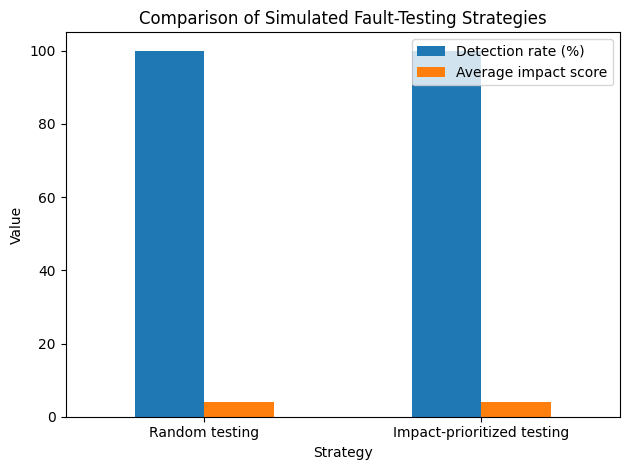

In [1]:

import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

# Simulated 16-bit detector readout
N_BITS = 16
N_TRIALS = 2000

# Illustrative fault impact scores, not measured hardware data
impact = {
    bit: (10 if bit in [0, 1, 2, 3] else 2)
    for bit in range(N_BITS)
}

def inject_fault(bit):
    """Simulate a bit flip in a 16-bit data word."""
    original = 0
    corrupted = original ^ (1 << bit)
    detected = corrupted.bit_count() % 2 == 1
    severity = impact[bit]
    return detected, severity

# Strategy A: choose a random bit
random_results = [
    inject_fault(random.randrange(N_BITS))
    for _ in range(N_TRIALS)
]

# Strategy B: prioritize high-impact bits
priorities = sorted(
    range(N_BITS),
    key=lambda bit: impact[bit],
    reverse=True
)

targeted_results = [
    inject_fault(priorities[i % len(priorities)])
    for i in range(N_TRIALS)
]

def summarize(name, results):
    detected = sum(result[0] for result in results)
    avg_impact = sum(result[1] for result in results) / len(results)
    return {
        "Strategy": name,
        "Faults tested": len(results),
        "Detection rate (%)": 100 * detected / len(results),
        "Average impact score": avg_impact
    }

results = pd.DataFrame([
    summarize("Random testing", random_results),
    summarize("Impact-prioritized testing", targeted_results)
])

display(results)

results.set_index("Strategy")[
    ["Detection rate (%)", "Average impact score"]
].plot(kind="bar", rot=0)
plt.title("Comparison of Simulated Fault-Testing Strategies")
plt.ylabel("Value")
plt.tight_layout()
plt.show()


Testing strategy comparison:


,Fault cases tested,Undetected faults encountered,Undetected fault rate (%)
Random testing,1000.0,392.0,39.2
Targeted testing,1000.0,1000.0,100.0


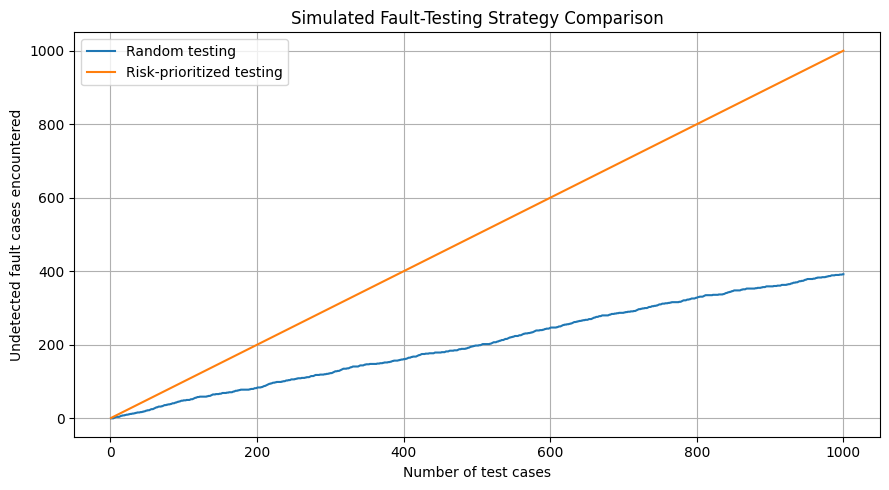


Fault distribution:


,Total_cases,Undetected_cases
fault_type,,
Data loss,1018,0
Four-bit flip,1016,1016
Single-bit flip,985,0
Three-bit flip,996,0
Two-bit flip,985,985


In [2]:

import random
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible experiment
random.seed(42)

N_CASES = 5000
TEST_BUDGET = 1000

# Simulated fault cases
faults = []

for i in range(N_CASES):
    fault_type = random.choice([
        "Single-bit flip",
        "Two-bit flip",
        "Three-bit flip",
        "Four-bit flip",
        "Data loss"
    ])

    if fault_type == "Data loss":
        detected = True  # Validity/sequence check
    else:
        bit_flips = {
            "Single-bit flip": 1,
            "Two-bit flip": 2,
            "Three-bit flip": 3,
            "Four-bit flip": 4
        }[fault_type]

        # Simplified parity check detects odd numbers of flips
        detected = (bit_flips % 2 == 1)

    faults.append({
        "case": i,
        "fault_type": fault_type,
        "detected": detected,
        "undetected": not detected
    })

df = pd.DataFrame(faults)

# Strategy A: random test order
random_order = df.sample(
    frac=1, random_state=10
).reset_index(drop=True)

# Strategy B: prioritize fault types that may evade parity
risk_order = {
    "Two-bit flip": 0,
    "Four-bit flip": 1,
    "Single-bit flip": 2,
    "Three-bit flip": 3,
    "Data loss": 4
}

targeted_order = df.copy()
targeted_order["priority"] = targeted_order[
    "fault_type"
].map(risk_order)

targeted_order = targeted_order.sort_values(
    ["priority", "case"]
).reset_index(drop=True)

def evaluate(order, budget):
    tested = order.head(budget)
    missed = int(tested["undetected"].sum())

    return {
        "Fault cases tested": len(tested),
        "Undetected faults encountered": missed,
        "Undetected fault rate (%)":
            100 * missed / len(tested)
    }

comparison = pd.DataFrame({
    "Random testing": evaluate(random_order, TEST_BUDGET),
    "Targeted testing": evaluate(targeted_order, TEST_BUDGET)
}).T

print("Testing strategy comparison:")
display(comparison)

# Plot the cumulative number of undetected faults encountered
def cumulative_misses(order, budget):
    return order["undetected"].astype(int).head(
        budget
    ).cumsum().reset_index(drop=True)

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, TEST_BUDGET + 1),
    cumulative_misses(random_order, TEST_BUDGET),
    label="Random testing"
)
plt.plot(
    range(1, TEST_BUDGET + 1),
    cumulative_misses(targeted_order, TEST_BUDGET),
    label="Risk-prioritized testing"
)

plt.xlabel("Number of test cases")
plt.ylabel("Undetected fault cases encountered")
plt.title("Simulated Fault-Testing Strategy Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nFault distribution:")
display(
    df.groupby("fault_type").agg(
        Total_cases=("case", "count"),
        Undetected_cases=("undetected", "sum")
    )
)


Overall results


,Detected faults,Undetected faults,Detection rate (%),Undetected rate (%)
Parity,2934.0,2066.0,58.68,41.32
Checksum,4949.0,51.0,98.98,1.02
CRC-8,5000.0,0.0,100.00,0.00


Method,CRC-8,Checksum,Parity
Fault type,,,
Burst error,0.0,0.00,66.22
Data loss,0.0,0.00,0.00
Single-bit flip,0.0,0.00,0.00
Two-bit flip,0.0,4.16,100.00


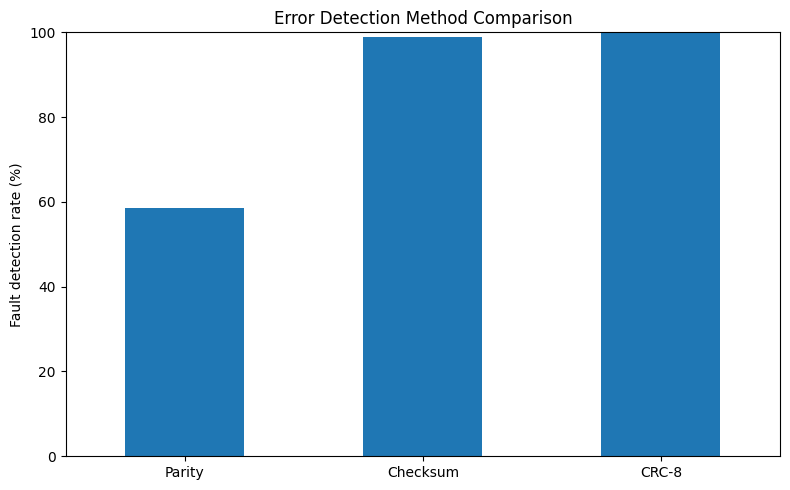

In [3]:

import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

N_TRIALS = 5000
DATA_BITS = 16
CRC_POLY = 0x07  # CRC-8 polynomial x^8 + x^2 + x + 1

# ---------- Error detection methods ----------

def parity_bit(word):
    return word.bit_count() % 2

def checksum(word):
    # Simple 8-bit checksum for this 16-bit word
    return ((word >> 8) + (word & 0xFF)) & 0xFF

def crc8(data, width=16):
    crc = 0
    for i in range(width - 1, -1, -1):
        bit = (data >> i) & 1
        top = (crc >> 7) & 1
        crc = (crc << 1) & 0xFF
        if top ^ bit:
            crc ^= CRC_POLY
    return crc

# ---------- Generate identical test cases ----------

def make_fault_case():
    original = random.getrandbits(DATA_BITS)
    fault_type = random.choice([
        "Single-bit flip",
        "Two-bit flip",
        "Burst error",
        "Data loss"
    ])

    corrupted = original

    if fault_type == "Single-bit flip":
        corrupted ^= 1 << random.randrange(DATA_BITS)

    elif fault_type == "Two-bit flip":
        positions = random.sample(range(DATA_BITS), 2)
        for p in positions:
            corrupted ^= 1 << p

    elif fault_type == "Burst error":
        start = random.randrange(DATA_BITS - 3)
        length = random.randint(2, 4)
        mask = ((1 << length) - 1) << start
        corrupted ^= mask

    elif fault_type == "Data loss":
        corrupted = 0

    return original, corrupted, fault_type

cases = [make_fault_case() for _ in range(N_TRIALS)]

# ---------- Evaluate detection methods ----------
# Data loss is detected by a separate frame-validity flag.
# A data value of zero alone cannot prove that data was lost.

def evaluate(method):
    missed = 0
    detected = 0

    for original, corrupted, fault_type in cases:
        if fault_type == "Data loss":
            error_detected = True

        elif method == "Parity":
            error_detected = (
                parity_bit(original) != parity_bit(corrupted)
            )

        elif method == "Checksum":
            error_detected = (
                checksum(original) != checksum(corrupted)
            )

        elif method == "CRC-8":
            error_detected = (
                crc8(original) != crc8(corrupted)
            )

        detected += int(error_detected)
        missed += int(not error_detected)

    return {
        "Detected faults": detected,
        "Undetected faults": missed,
        "Detection rate (%)": 100 * detected / N_TRIALS,
        "Undetected rate (%)": 100 * missed / N_TRIALS
    }

results = pd.DataFrame({
    method: evaluate(method)
    for method in ["Parity", "Checksum", "CRC-8"]
}).T

print("Overall results")
display(results.round(2))

# ---------- Compare fault types ----------

rows = []

for fault_type in sorted(set(c[2] for c in cases)):
    subset = [c for c in cases if c[2] == fault_type]

    for method in ["Parity", "Checksum", "CRC-8"]:
        missed = 0

        for original, corrupted, kind in subset:
            if kind == "Data loss":
                error_detected = True
            elif method == "Parity":
                error_detected = (
                    parity_bit(original) != parity_bit(corrupted)
                )
            elif method == "Checksum":
                error_detected = (
                    checksum(original) != checksum(corrupted)
                )
            else:
                error_detected = (
                    crc8(original) != crc8(corrupted)
                )

            missed += int(not error_detected)

        rows.append({
            "Fault type": fault_type,
            "Method": method,
            "Undetected rate (%)": 100 * missed / len(subset)
        })

by_fault = pd.DataFrame(rows)
display(by_fault.pivot(
    index="Fault type",
    columns="Method",
    values="Undetected rate (%)"
).round(2))

# ---------- Plot ----------

results["Detection rate (%)"].plot(
    kind="bar", rot=0, figsize=(8, 5)
)
plt.ylabel("Fault detection rate (%)")
plt.title("Error Detection Method Comparison")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


Detection performance by number of flipped bits:


,Cases,Parity_detected,CRC_detected,Parity detection (%),CRC detection (%)
Bits flipped,,,,,
1,16,16,16,100.0,100.00
2,120,0,120,0.0,100.00
3,560,560,560,100.0,100.00
4,1820,0,1804,0.0,99.12
5,4368,4368,4368,100.0,100.00
6,8008,0,7957,0.0,99.36
7,11440,11440,11440,100.0,100.00
8,12870,0,12753,0.0,99.09
9,11440,11440,11440,100.0,100.00


Overall results:


,Method,Faults detected,Detection rate (%)
0,Parity,32768,50.001
1,CRC-8,65280,99.611


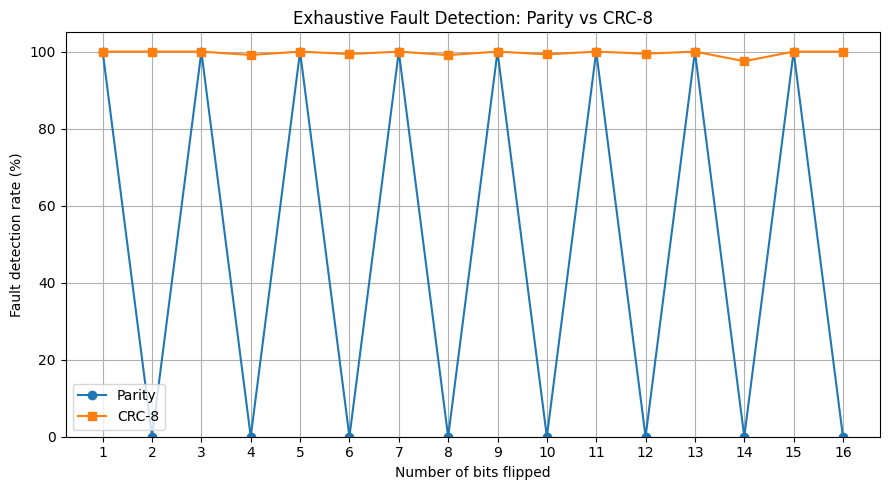

Examples of faults missed by parity:


,Fault mask,Bits flipped,Parity detected,CRC detected
2,0x0003,2,False,True
4,0x0005,2,False,True
5,0x0006,2,False,True
8,0x0009,2,False,True
9,0x000A,2,False,True


Examples of faults missed by CRC-8:


,Fault mask,Bits flipped,Parity detected,CRC detected
262,0x0107,4,False,False
525,0x020E,4,False,False
776,0x0309,4,False,False
1051,0x041C,4,False,False
1306,0x051B,6,False,False


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

DATA = 0xA53C
WIDTH = 16
TOTAL_MASKS = (1 << WIDTH) - 1

# Same CRC-8 algorithm as the Verilog design
def crc8(data):
    crc = 0

    for i in range(15, -1, -1):
        bit = (data >> i) & 1
        feedback = ((crc >> 7) & 1) ^ bit

        crc = (crc << 1) & 0xFF

        if feedback:
            crc ^= 0x07

    return crc

original_parity = DATA.bit_count() % 2
original_crc = crc8(DATA)

results = []

# Enumerate every nonzero 16-bit fault mask
for mask in range(1, TOTAL_MASKS + 1):
    corrupted = DATA ^ mask
    flipped_bits = mask.bit_count()

    parity_detected = (
        (corrupted.bit_count() % 2) != original_parity
    )

    crc_detected = crc8(corrupted) != original_crc

    results.append({
        "Fault mask": f"0x{mask:04X}",
        "Bits flipped": flipped_bits,
        "Parity detected": parity_detected,
        "CRC detected": crc_detected
    })

df = pd.DataFrame(results)

# Summarize results by the number of flipped bits
summary = df.groupby("Bits flipped").agg(
    Cases=("Fault mask", "count"),
    Parity_detected=("Parity detected", "sum"),
    CRC_detected=("CRC detected", "sum")
)

summary["Parity detection (%)"] = (
    100 * summary["Parity_detected"] / summary["Cases"]
)

summary["CRC detection (%)"] = (
    100 * summary["CRC_detected"] / summary["Cases"]
)

print("Detection performance by number of flipped bits:")
display(summary.round(2))

# Overall comparison
overall = pd.DataFrame({
    "Method": ["Parity", "CRC-8"],
    "Faults detected": [
        int(df["Parity detected"].sum()),
        int(df["CRC detected"].sum())
    ]
})

overall["Detection rate (%)"] = (
    100 * overall["Faults detected"] / len(df)
)

print("Overall results:")
display(overall.round(3))

# Plot detection rate against number of flipped bits
plt.figure(figsize=(9, 5))

plt.plot(
    summary.index,
    summary["Parity detection (%)"],
    marker="o",
    label="Parity"
)

plt.plot(
    summary.index,
    summary["CRC detection (%)"],
    marker="s",
    label="CRC-8"
)

plt.xlabel("Number of bits flipped")
plt.ylabel("Fault detection rate (%)")
plt.title("Exhaustive Fault Detection: Parity vs CRC-8")
plt.xticks(range(1, WIDTH + 1))
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Show a few fault patterns missed by each method
print("Examples of faults missed by parity:")
display(df[~df["Parity detected"]].head(5))

print("Examples of faults missed by CRC-8:")
display(df[~df["CRC detected"]].head(5))


,Burst length (bits),Patterns tested,Parity detection (%),CRC-8 detection (%)
0,2,15,0.0,100.0
1,3,14,100.0,100.0
2,4,13,0.0,100.0
3,5,12,100.0,100.0
4,6,11,0.0,100.0
5,7,10,100.0,100.0
6,8,9,0.0,100.0


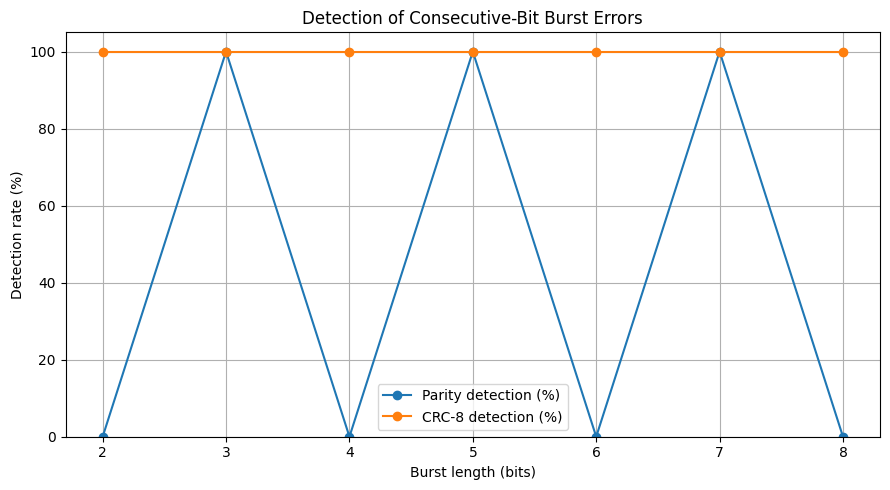

In [5]:

import pandas as pd
import matplotlib.pyplot as plt

def burst_mask(start, length):
    return ((1 << length) - 1) << start

data = 0xA53C
width = 16

def parity(word):
    return word.bit_count() % 2

def crc8(word):
    crc = 0
    for i in range(15, -1, -1):
        feedback = ((crc >> 7) & 1) ^ ((word >> i) & 1)
        crc = (crc << 1) & 0xFF
        if feedback:
            crc ^= 0x07
    return crc

original_parity = parity(data)
original_crc = crc8(data)

rows = []

# Burst length is the span from the first flipped bit
# to the last flipped bit, including both endpoints.
for length in range(2, 9):
    total = 0
    parity_missed = 0
    crc_missed = 0

    for start in range(width - length + 1):
        mask = burst_mask(start, length)
        corrupted = data ^ mask

        total += 1
        parity_missed += (
            parity(corrupted) == original_parity
        )
        crc_missed += (
            crc8(corrupted) == original_crc
        )

    rows.append({
        "Burst length (bits)": length,
        "Patterns tested": total,
        "Parity detection (%)":
            100 * (1 - parity_missed / total),
        "CRC-8 detection (%)":
            100 * (1 - crc_missed / total)
    })

burst_results = pd.DataFrame(rows)
display(burst_results.round(2))

burst_results.set_index("Burst length (bits)")[
    ["Parity detection (%)", "CRC-8 detection (%)"]
].plot(marker="o", figsize=(9, 5))

plt.ylabel("Detection rate (%)")
plt.title("Detection of Consecutive-Bit Burst Errors")
plt.ylim(0, 105)
plt.grid(True)
plt.tight_layout()
plt.show()



In [6]:

# Python reference checks for your CRC-8 algorithm

def crc8(data):
    crc = 0
    for i in range(15, -1, -1):
        feedback = ((crc >> 7) & 1) ^ ((data >> i) & 1)
        crc = (crc << 1) & 0xFF
        if feedback:
            crc ^= 0x07
    return crc

test_words = [0x0000, 0x0001, 0x1234, 0xABCD, 0x005A, 0xFFFF]

print("Input word | CRC-8")
for word in test_words:
    print(f"0x{word:04X}   | 0x{crc8(word):02X}")

print("\nNow compare these values with the CRC values")
print("from your Verilog simulation for the same words.")


Input word | CRC-8
0x0000   | 0x00
0x0001   | 0x07
0x1234   | 0xF1
0xABCD   | 0xE2
0x005A   | 0x81
0xFFFF   | 0x24

Now compare these values with the CRC values
from your Verilog simulation for the same words.


In [7]:

def crc8(data):
    crc = 0x00
    for bit in range(15, -1, -1):
        feedback = ((crc >> 7) & 1) ^ ((data >> bit) & 1)
        crc = (crc << 1) & 0xFF
        if feedback:
            crc ^= 0x07
    return crc


data = 0xA53C
reference_crc = crc8(data)
reference_parity = data.bit_count() % 2

total = 0
parity_detected = 0
crc_detected = 0
both_detected = 0
parity_missed_crc_detected = 0
crc_missed = 0

for mask in range(1, 65536):
    received = data ^ mask

    parity_error = (received.bit_count() % 2) != reference_parity
    crc_error = crc8(received) != reference_crc

    total += 1
    parity_detected += parity_error
    crc_detected += crc_error
    both_detected += parity_error and crc_error
    parity_missed_crc_detected += (not parity_error) and crc_error
    crc_missed += not crc_error

print("FAULT-INJECTION RESULTS")
print("-----------------------")
print(f"Data word:                  0x{data:04X}")
print(f"Total nonzero fault masks:  {total}")
print(f"Parity detected:            {parity_detected}")
print(f"CRC-8 detected:              {crc_detected}")
print(f"Both detected:               {both_detected}")
print(f"Parity missed, CRC detected: {parity_missed_crc_detected}")
print(f"CRC-8 missed:                 {crc_missed}")
print()
print(f"Parity detection rate: {100 * parity_detected / total:.3f}%")
print(f"CRC-8 detection rate:   {100 * crc_detected / total:.3f}%")
print(f"CRC-8 miss rate:        {100 * crc_missed / total:.3f}%")


FAULT-INJECTION RESULTS
-----------------------
Data word:                  0xA53C
Total nonzero fault masks:  65535
Parity detected:            32768
CRC-8 detected:              65280
Both detected:               32768
Parity missed, CRC detected: 32512
CRC-8 missed:                 255

Parity detection rate: 50.001%
CRC-8 detection rate:   99.611%
CRC-8 miss rate:        0.389%


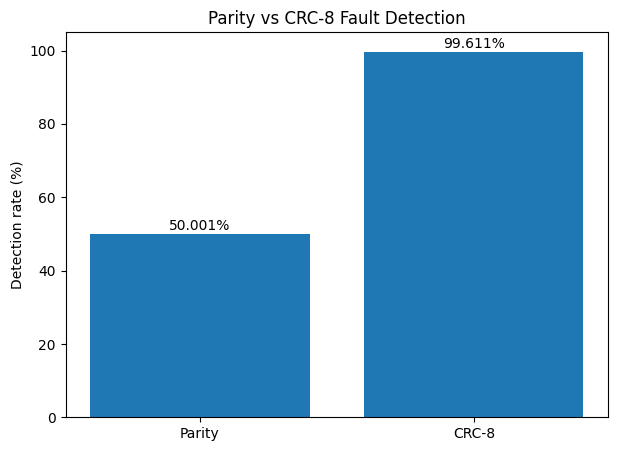

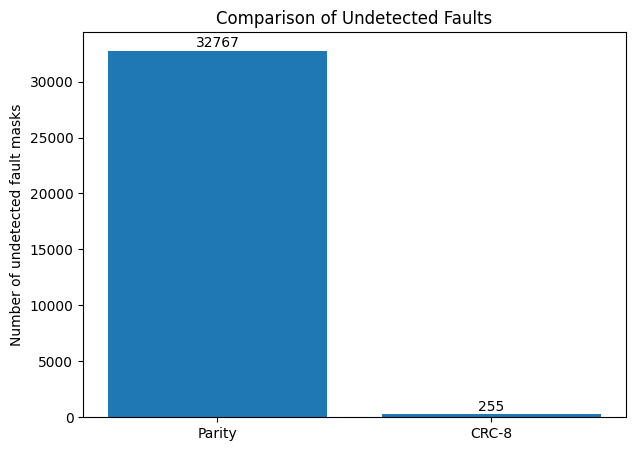

Parity undetected: 32767
CRC-8 undetected: 255


In [8]:
import matplotlib.pyplot as plt

total = 65535

# Results from your experiment
parity_detected = 32768
crc_detected = 65280
parity_missed = total - parity_detected
crc_missed = total - crc_detected

# Graph 1: Detection rate
methods = ["Parity", "CRC-8"]
rates = [
    parity_detected / total * 100,
    crc_detected / total * 100
]

plt.figure(figsize=(7, 5))
plt.bar(methods, rates)
plt.ylabel("Detection rate (%)")
plt.title("Parity vs CRC-8 Fault Detection")
plt.ylim(0, 105)

for i, rate in enumerate(rates):
    plt.text(i, rate + 1, f"{rate:.3f}%", ha="center")

plt.show()

# Graph 2: Undetected faults
missed = [parity_missed, crc_missed]

plt.figure(figsize=(7, 5))
plt.bar(methods, missed)
plt.ylabel("Number of undetected fault masks")
plt.title("Comparison of Undetected Faults")

for i, count in enumerate(missed):
    plt.text(i, count + 300, str(count), ha="center")

plt.show()

print("Parity undetected:", parity_missed)
print("CRC-8 undetected:", crc_missed)